In [ ]:
#Step-1
#Loads the Pandas library into Python's memory so one can access its spreadsheet-like functions.
import pandas as pd

# Load dataset using a verified raw GitHub URL

url = 'https://raw.githubusercontent.com/SubhrojitPatra/imdb-movie-analytics/main/IMDB-Movie-Data.csv'


# Read dataset into cloud memory
df = pd.read_csv(url)

# Display total count and preview top 5 rows
print(f"Database loaded successfully! Total movies: {len(df)}")
display(df.head())

Database loaded successfully! Total movies: 1000


,Rank,Title,Genre,Description,Director,Actors,Year,Runtime (Minutes),Rating,Votes,Revenue (Millions),Metascore
0,1,Guardians of the Galaxy,"Action,Adventure,Sci-Fi",A group of intergalactic criminals are forced ...,James Gunn,"Chris Pratt, Vin Diesel, Bradley Cooper, Zoe S...",2014,121,8.1,757074,333.13,76.0
1,2,Prometheus,"Adventure,Mystery,Sci-Fi","Following clues to the origin of mankind, a te...",Ridley Scott,"Noomi Rapace, Logan Marshall-Green, Michael Fa...",2012,124,7.0,485820,126.46,65.0
2,3,Split,"Horror,Thriller",Three girls are kidnapped by a man with a diag...,M. Night Shyamalan,"James McAvoy, Anya Taylor-Joy, Haley Lu Richar...",2016,117,7.3,157606,138.12,62.0
3,4,Sing,"Animation,Comedy,Family","In a city of humanoid animals, a hustling thea...",Christophe Lourdelet,"Matthew McConaughey,Reese Witherspoon, Seth Ma...",2016,108,7.2,60545,270.32,59.0
4,5,Suicide Squad,"Action,Adventure,Fantasy",A secret government agency recruits some of th...,David Ayer,"Will Smith, Jared Leto, Margot Robbie, Viola D...",2016,123,6.2,393727,325.02,40.0


In [ ]:
#Step-2
#Displays the total count of rows, column names, memory usage, and column data types
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Rank                1000 non-null   int64  
 1   Title               1000 non-null   object 
 2   Genre               1000 non-null   object 
 3   Description         1000 non-null   object 
 4   Director            1000 non-null   object 
 5   Actors              1000 non-null   object 
 6   Year                1000 non-null   int64  
 7   Runtime (Minutes)   1000 non-null   int64  
 8   Rating              1000 non-null   float64
 9   Votes               1000 non-null   int64  
 10  Revenue (Millions)  872 non-null    float64
 11  Metascore           936 non-null    float64
dtypes: float64(3), int64(4), object(5)
memory usage: 93.9+ KB


In [ ]:
#step-3
"""Column headers with spaces or capital letters (like "Revenue (Millions)") cause syntax errors.
df.columns.str.replace(' ', '_'): Replaces all spaces with underscores.
.str.lower(): Converts all column headers to lowercase text so you never have to guess capitalization.
"""

df.columns = df.columns.str.replace(' ','_').str.lower()
print(df.columns.tolist())

['rank', 'title', 'genre', 'description', 'director', 'actors', 'year', 'runtime_(minutes)', 'rating', 'votes', 'revenue_(millions)', 'metascore']


In [ ]:
#step-4
"""
df.isnull(): Scans every cell and marks empty cells as True and filled cells as False.

.sum(): Counts up all the True values for each column so you can see where data is missing.
"""

print(df.isnull().sum())

rank                    0
title                   0
genre                   0
description             0
director                0
actors                  0
year                    0
runtime_(minutes)       0
rating                  0
votes                   0
revenue_(millions)    128
metascore              64
dtype: int64


In [ ]:
#step-5
"""
df.dropna(subset=[...]): Removes only the rows where values in revenue_(millions) or metascore are missing, saving the cleaned result into a new variable called df_clean.

Why assign to df_clean: It keeps your original dataset (df) untouched in memory while giving you a fresh table ready for analysis.
"""

df_clean = df.dropna(subset=['revenue_(millions)', 'metascore'])
print(f"Cleaned rows: {len(df_clean)} (dropped {len(df) - len(df_clean)} empty rows)")

Cleaned rows: 838 (dropped 162 empty rows)


In [ ]:
#step-6
"""
After completing Data ingestion and cleaning now we can start analyzing the data, and the first step is exploratory data analysis.
Here we will try to answer some basic questions from our database...
"""
# Now our first question is make a list of 10 highest grossing movies.
top_10_revenue = df_clean.sort_values(by='revenue_(millions)',ascending = False)[['title','revenue_(millions)','rating']].head(10)
display(top_10_revenue)
# Now our first question is make a list of 10 highest rating movies.
top_10_rating = df_clean.sort_values(by='rating',ascending = False)[['title','rating','votes','year']].head(10)
display(top_10_rating)

,title,revenue_(millions),rating
50,Star Wars: Episode VII - The Force Awakens,936.63,8.1
87,Avatar,760.51,7.8
85,Jurassic World,652.18,7.0
76,The Avengers,623.28,8.1
54,The Dark Knight,533.32,9.0
12,Rogue One,532.17,7.9
119,Finding Dory,486.29,7.4
94,Avengers: Age of Ultron,458.99,7.4
124,The Dark Knight Rises,448.13,8.5
578,The Hunger Games: Catching Fire,424.65,7.6


,title,rating,votes,year
54,The Dark Knight,9.0,1791916,2008
80,Inception,8.8,1583625,2010
36,Interstellar,8.6,1047747,2014
96,Kimi no na wa,8.6,34110,2016
249,The Intouchables,8.6,557965,2011
124,The Dark Knight Rises,8.5,1222645,2012
99,The Departed,8.5,937414,2006
64,The Prestige,8.5,913152,2006
991,Taare Zameen Par,8.5,102697,2007
476,The Lives of Others,8.5,278103,2006


In [ ]:
#step-7
#Now, Let's get an overall statistical summary (mean, median, min, max, percentiles) for numerical columns like ratings, revenue, and votes.
df_clean[['revenue_(millions)','rating','votes']].describe()

,revenue_(millions),rating,votes
count,838.000000,838.000000,8.380000e+02
mean,84.564558,6.814320,1.932303e+05
std,104.520227,0.877754,1.930990e+05
min,0.000000,1.900000,1.780000e+02
25%,13.967500,6.300000,6.127650e+04
50%,48.150000,6.900000,1.368795e+05
75%,116.800000,7.500000,2.710830e+05
max,936.630000,9.000000,1.791916e+06


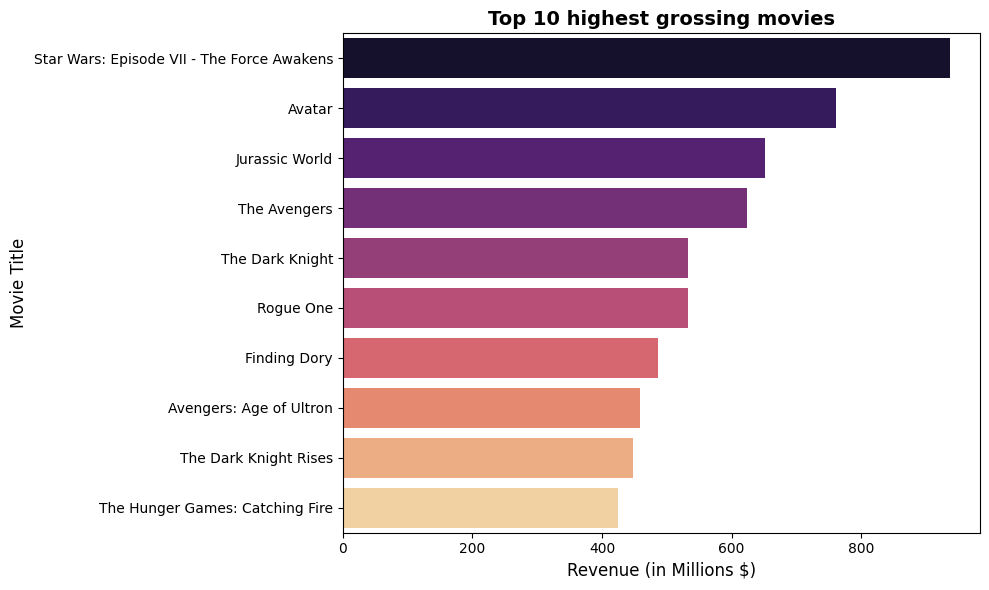

In [ ]:
#step-8
#DATA VISUALIZATION
import matplotlib.pyplot as plt
import seaborn as sns

# "matplotlib.pyplot" a very important library for data visualization where it provides us the axis control and plot layouts...
# "seaborn" is also an important library where it provides modern and high level drawing...


#set chart style
plt.figure(figsize=(10,6))  #Creates an empty chart window with a specific size: 10 inches wide by 6 inches tall.
# sns.barplot - Generates the horizontal bar chart.
sns.barplot(
    data = top_10_revenue,   #Tells Seaborn to read values directly from top 10 movies table.
    x= 'revenue_(millions)',
    y = 'title',
    # Sets revenue on the horizontal X-axis and movie titles on the vertical Y-axis
    hue='title',
    legend=False,
    #FutureWarning:
     #Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.
    palette = 'magma'    #Applies a pre-built color gradient, giving each bar a distinct color shade from dark purple to bright orange/yellow.
)

# Add titles and lables
plt.title('Top 10 highest grossing movies', fontsize=14 ,fontweight='bold')
plt.xlabel('Revenue (in Millions $)', fontsize=12)
plt.ylabel('Movie Title', fontsize=12)
plt.tight_layout()

"""
plt.title(...), plt.xlabel(...), plt.ylabel(...)
Adds descriptive text to the graph. fontsize adjusts text size, and fontweight='bold' makes the main header stand out.
plt.tight_layout()
Automatically adjusts the margins around the plot so long movie titles don't get chopped off at the left edge.
"""

# Render Chart
plt.show()             #Clears the background settings and renders the final graphic directly inside your Colab notebook.

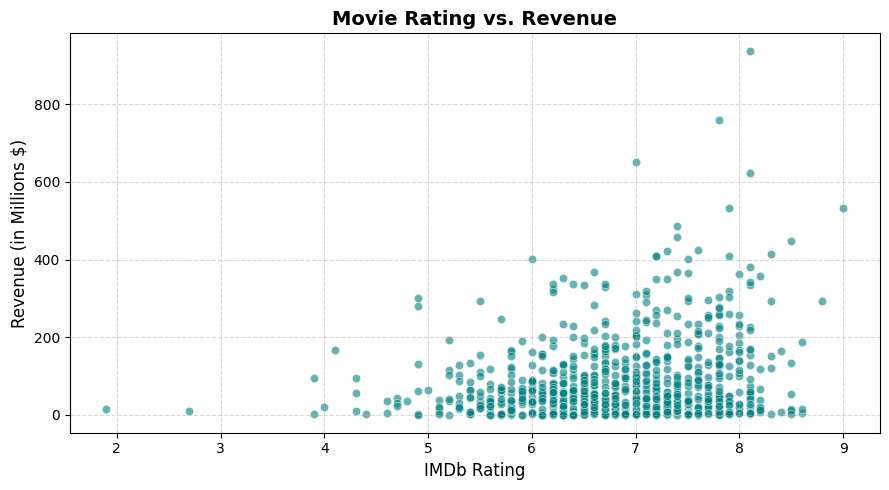

In [ ]:
#step-9
plt.figure(figsize=(9, 5))
sns.scatterplot(
    data=df_clean,
    x='rating',
    y='revenue_(millions)',
    alpha=0.6,
    color='teal'
)

# Add trend line and labels
plt.title('Movie Rating vs. Revenue', fontsize=14, fontweight='bold')
plt.xlabel('IMDb Rating', fontsize=12)
plt.ylabel('Revenue (in Millions $)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()

# Render chart
plt.show()